### 1. Import Dependecies

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2. Reading Dataset

In [2]:
import os

data_path = "../../data/processed/Feature_Overviewed.csv"
if not os.path.exists(data_path):
    data_path = "../../data/processed/Initial_Data_Assessed.csv"

df = pd.read_csv(data_path)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3. Analysis

#### 3.1 Count churn values

In [3]:
# 1. Count churn values
churn_counts = df['Churn'].value_counts()
print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


#### 3.2 Churn rate in %

In [4]:
churn_rate = df['Churn'].value_counts(normalize=True) * 100
print(churn_rate)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


#### 3.3 Visualize Churn Distribution

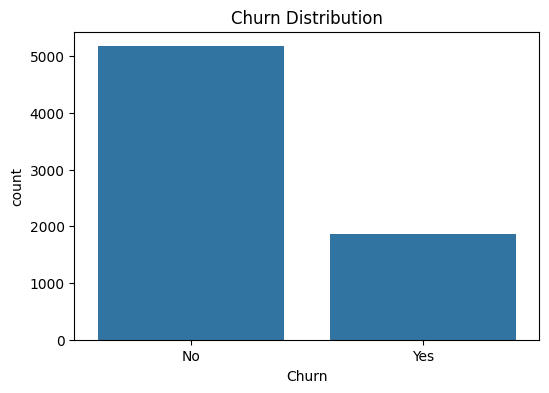

In [5]:
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

In [6]:
imbalance_ratio = churn_counts['No'] / churn_counts['Yes']
print("Imbalance ratio (No/Yes):", imbalance_ratio)

Imbalance ratio (No/Yes): 2.7683253076511503


#### 3.4 Churn % per segment

In [7]:
segments = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
            'Contract', 'PaymentMethod', 'InternetService']

for col in segments:
    churn_segment = df.groupby(col)['Churn'].value_counts(normalize=True).unstack()
    print(f"\nChurn rate by {col}:")
    print(churn_segment)


Churn rate by gender:
Churn         No       Yes
gender                    
Female  0.730791  0.269209
Male    0.738397  0.261603

Churn rate by SeniorCitizen:
Churn                No       Yes
SeniorCitizen                    
0              0.763938  0.236062
1              0.583187  0.416813

Churn rate by Partner:
Churn          No       Yes
Partner                    
No       0.670420  0.329580
Yes      0.803351  0.196649

Churn rate by Dependents:
Churn             No       Yes
Dependents                    
No          0.687209  0.312791
Yes         0.845498  0.154502

Churn rate by Contract:
Churn                 No       Yes
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319

Churn rate by PaymentMethod:
Churn                            No       Yes
PaymentMethod                                
Bank transfer (automatic)  0.832902  0.167098
Credit card (automatic)    0.847569  0.152431
El

#### 3.5 Visualize churn per segment

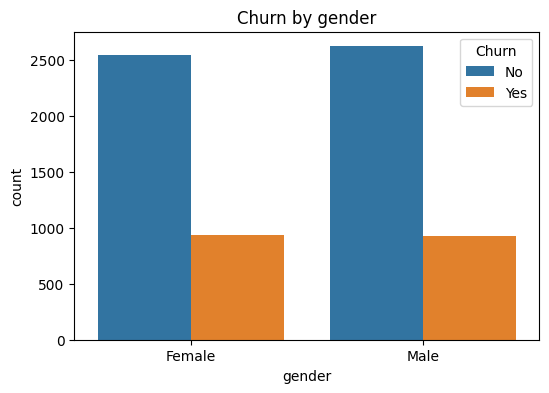

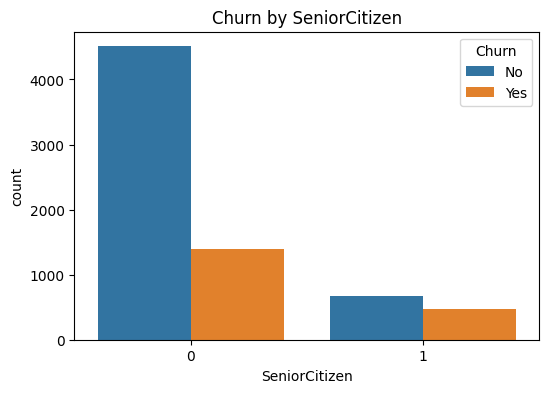

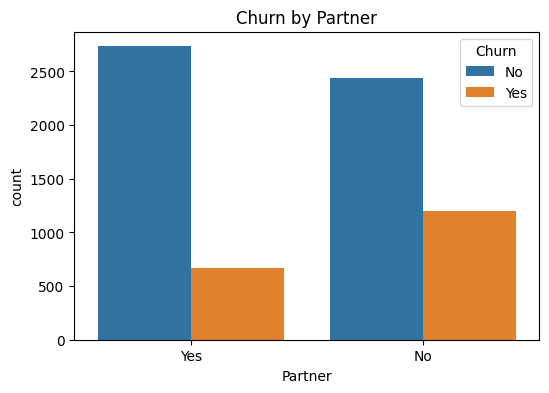

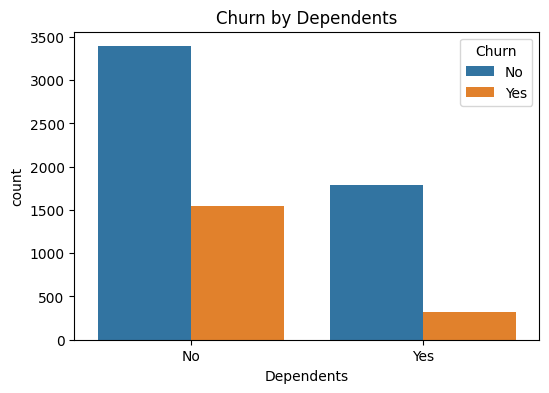

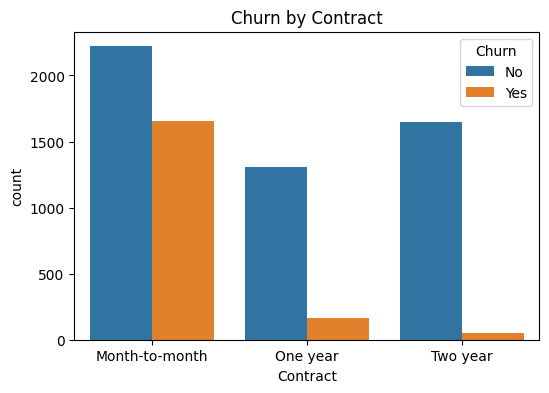

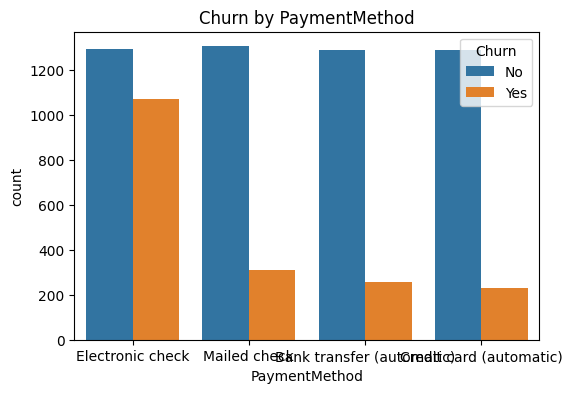

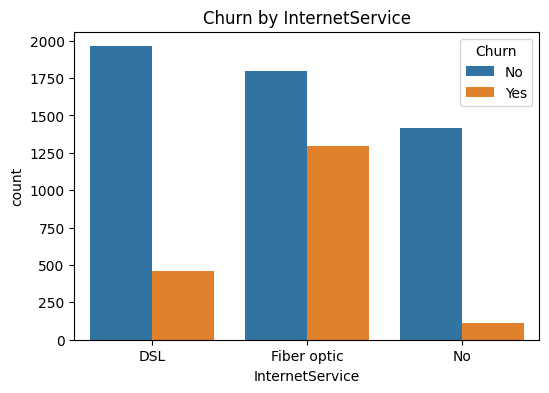

In [8]:
for col in segments:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue='Churn', data=df)
    plt.title(f'Churn by {col}')
    plt.show()

### 4. Advanced Univariate Analysis

#### 4.1 Categorizing coloumns

In [9]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_cols = [col for col in df.columns if col not in numerical_cols and col not in ['Churn', 'customerID']]


In [10]:
print(f"Numerical columns: {numerical_cols}")
print(f"categorical columns: {categorical_cols}")

Numerical columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


##### 4.1.1 Numerical features Visualization


Summary stats for tenure:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


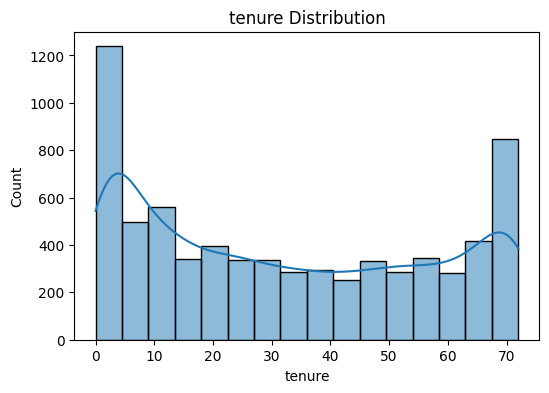

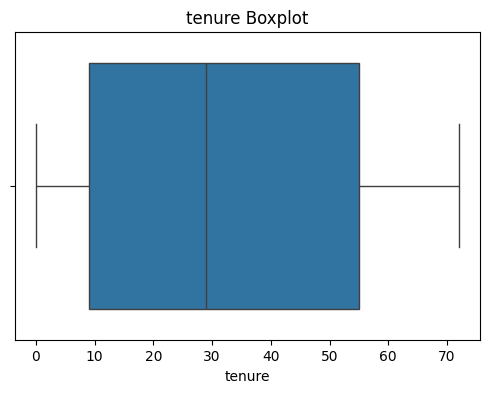


Summary stats for MonthlyCharges:
count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64


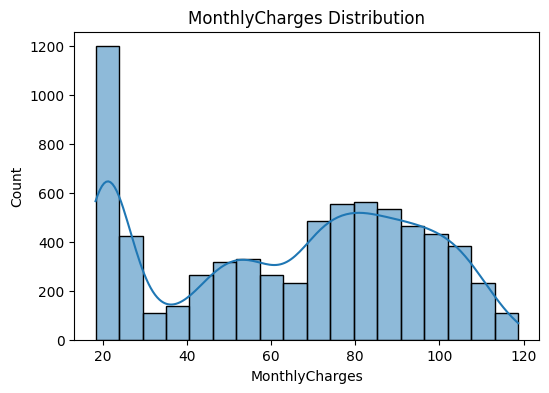

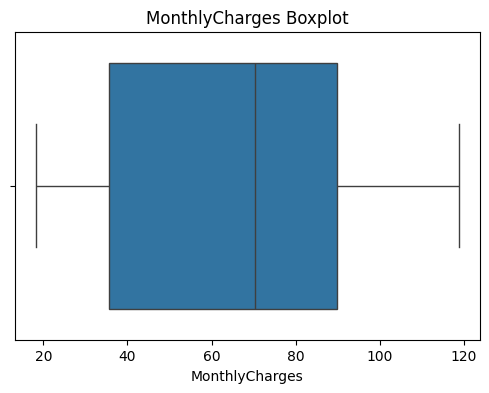


Summary stats for TotalCharges:
count    7043.000000
mean     2281.916928
std      2265.270398
min        18.800000
25%       402.225000
50%      1397.475000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


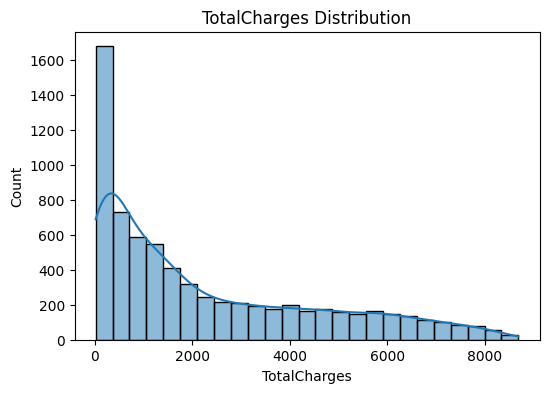

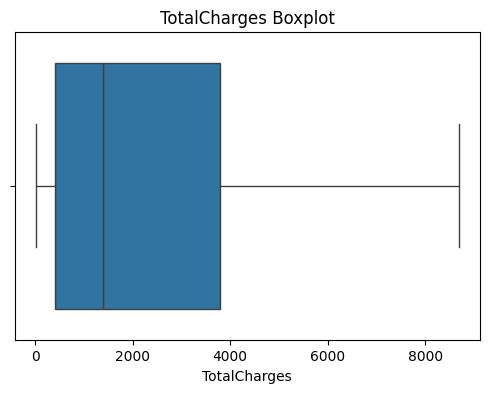

In [11]:
for col in numerical_cols:
    print(f"\nSummary stats for {col}:")
    print(df[col].describe())
    
    # Distribution plot
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'{col} Distribution')
    plt.show()
    
    # Boxplot for outlier detection
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f'{col} Boxplot')
    plt.show()

##### 4.1.2 IQR method

In [12]:
def detect_outliers_iqr(data):
    # Ensure data is numeric and handle missing values safely
    numeric_data = pd.to_numeric(data, errors='coerce')
    
    # Use pandas quantile (skips NaNs by default)
    Q1 = numeric_data.quantile(0.25)
    Q3 = numeric_data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (numeric_data < lower_bound) | (numeric_data > upper_bound)
    return outliers, lower_bound, upper_bound, IQR

for col in numerical_cols:
    outliers, lower, upper, iqr = detect_outliers_iqr(df[col])
    print(f"\n--- {col} ---")
    print(f"IQR: {iqr:.2f} | Bounds: [{lower:.2f}, {upper:.2f}]")
    print(f"Outliers count: {outliers.sum()} ({outliers.mean() * 100:.2f}%)")

tenure : 0 outliers (0.00%)
MonthlyCharges : 0 outliers (0.00%)
TotalCharges : 0 outliers (0.00%)


##### 4.1.3 Z-score Method

In [13]:
def detect_outliers_zscore(data, threshold=3):
    """
    Returns a boolean Series indicating outliers based on Z-score.
    threshold: number of standard deviations to consider as outlier
    """
    numeric_data = pd.to_numeric(data, errors='coerce')
    z_scores = (numeric_data - numeric_data.mean()) / numeric_data.std()
    return (z_scores > threshold) | (z_scores < -threshold)

for col in numerical_cols:
    outliers = detect_outliers_zscore(df[col])
    print(f"{col} : {outliers.sum()} outliers ({outliers.mean() * 100:.2f}%)")

tenure : 0 outliers (0.00%)
MonthlyCharges : 0 outliers (0.00%)
TotalCharges : 0 outliers (0.00%)


#### 4.2 Categorical features Visualization


Value counts for gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64


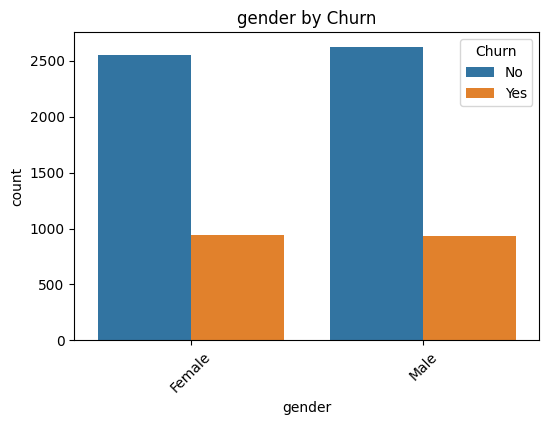


Value counts for SeniorCitizen:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


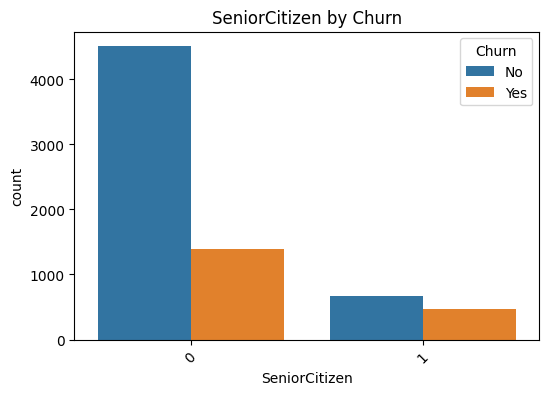


Value counts for Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64


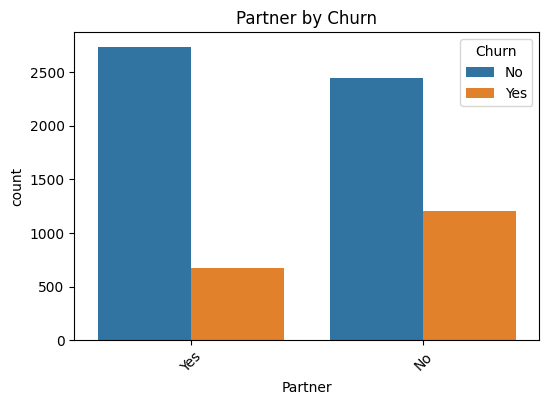


Value counts for Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64


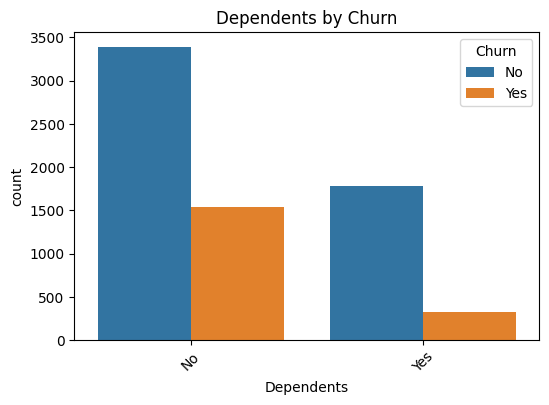


Value counts for PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64


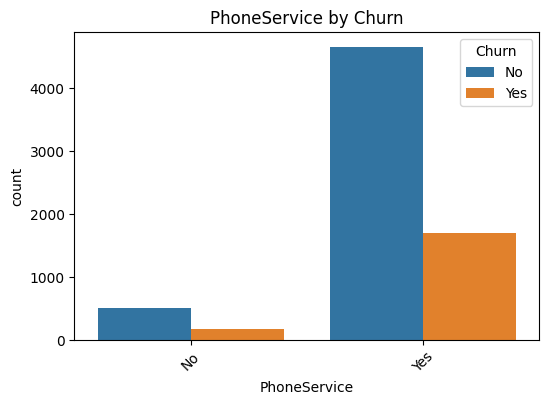


Value counts for MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


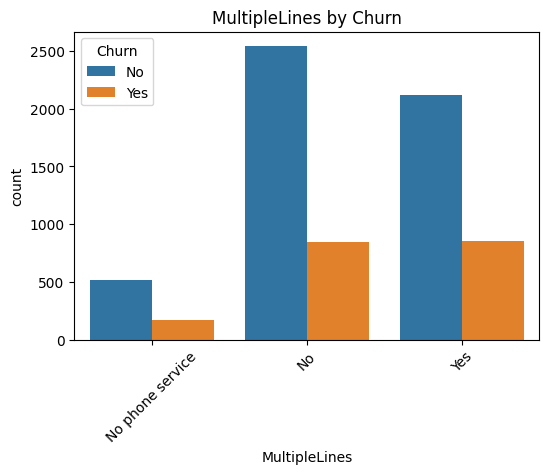


Value counts for InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


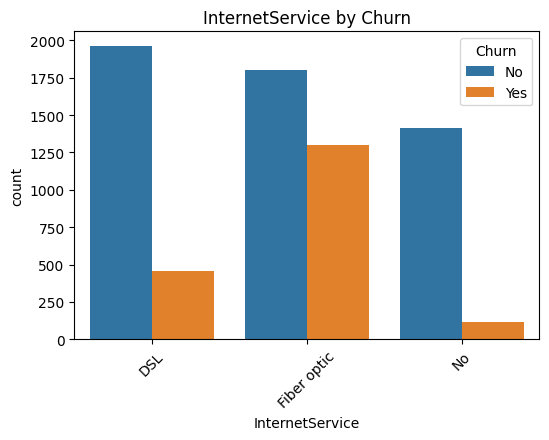


Value counts for OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


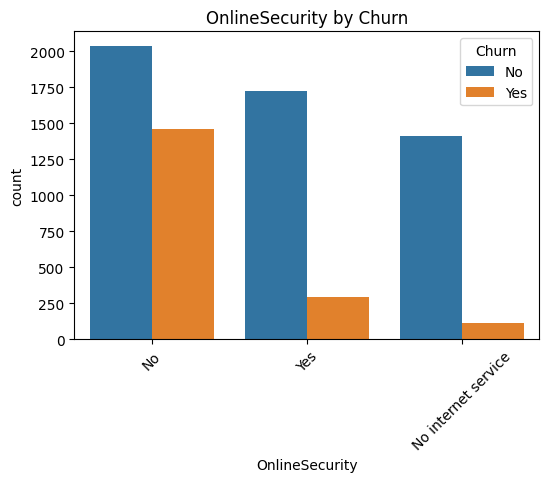


Value counts for OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64


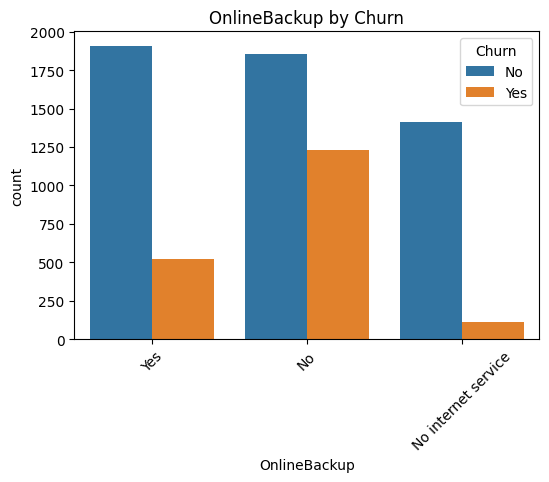


Value counts for DeviceProtection:
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64


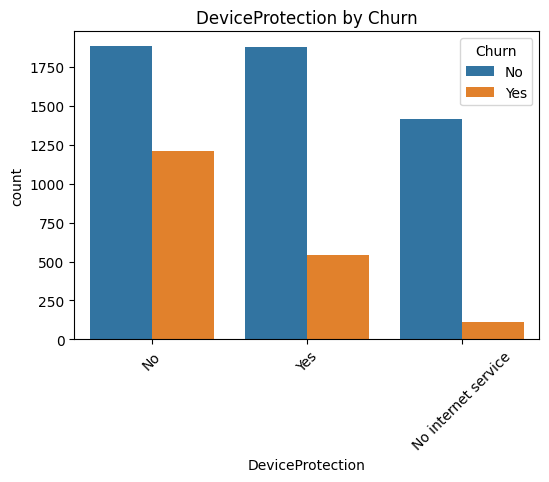


Value counts for TechSupport:
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64


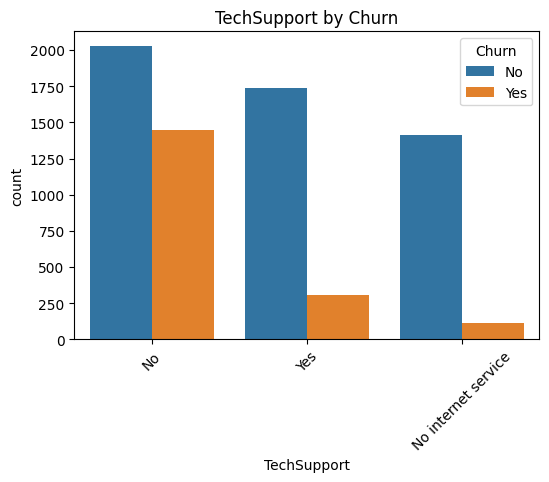


Value counts for StreamingTV:
StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64


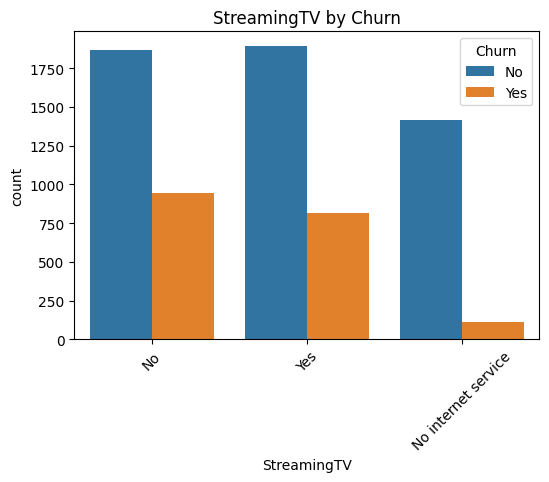


Value counts for StreamingMovies:
StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64


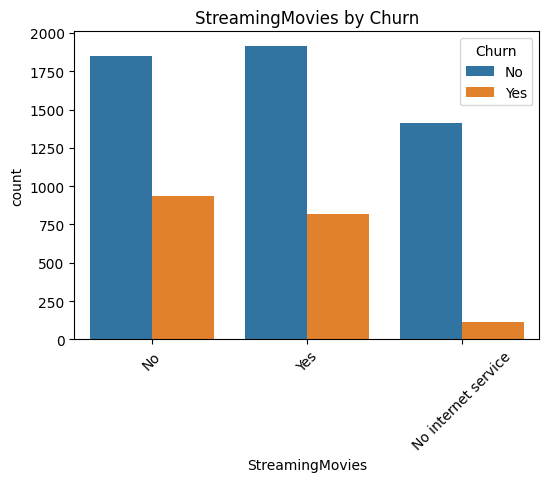


Value counts for Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


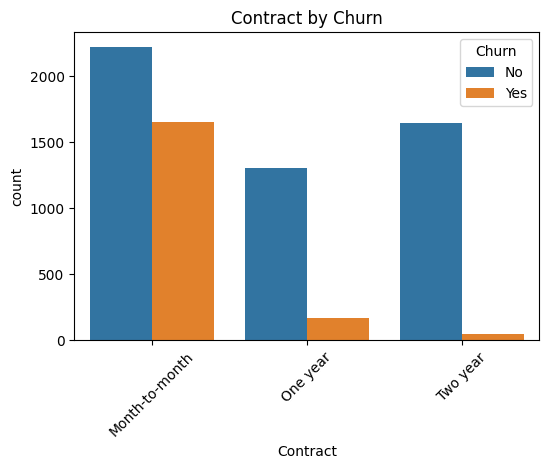


Value counts for PaperlessBilling:
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64


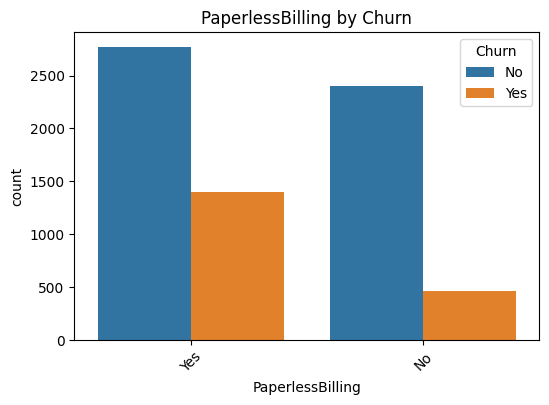


Value counts for PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


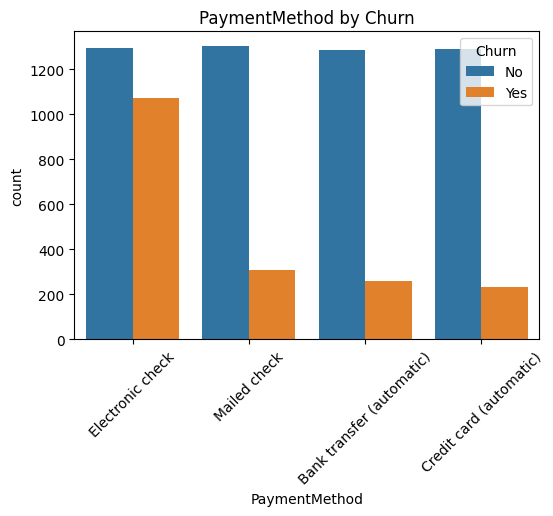

In [14]:
for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())
    
    # 1. Univariate Distribution (Single Variable)
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    # 2. Bivariate breakdown with Churn
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, hue='Churn', data=df)
    plt.title(f'{col} by Churn')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [15]:
for col in categorical_cols:
    freq = df[col].value_counts(normalize=True)
    rare = freq[freq < 0.01]  # categories <1% of data
    if not rare.empty:
        print(f"{col} has rare categories:\n{rare}")

In [16]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
# Save the final cleaned DataFrame for downstream use if needed
# (z-score columns were detected during outlier analysis but not added to df)
print("Final dataframe shape:", df.shape)
print("Columns:", list(df.columns))